# **Module 09: Cluster Analysis**

---

## 📌 Overview

**Cluster Analysis** is an **unsupervised learning** technique whose goal is to divide a set of observations into homogeneous groups (*clusters*), such that elements within the same group are highly similar to each other and distinct from elements in other groups.

Unlike supervised methods, there is no pre-labeled target variable here. This approach is widely used in customer segmentation, behavioral profiling, document organization, and anomaly detection. In this notebook, we will explore distance metrics, the main hierarchical and non-hierarchical algorithms, and how to evaluate cluster quality in Python.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Understand the logic of unsupervised clustering** and the importance of feature scaling before calculating distances.
* **Choose and apply dissimilarity and distance measures** (Euclidean, Manhattan, Cosine, Mahalanobis, and distances for binary/categorical data).
* **Implement and interpret Hierarchical Clustering**, exploring linkage criteria (*Single*, *Complete*, *Average*, and *Ward*) and reading **dendrograms**.
* **Apply the K-Means algorithm** (non-hierarchical / partitional clustering), understanding centroid initialization and convergence.
* **Determine the optimal number of clusters ($k$)** and evaluate partition quality using the **Elbow Method**, **Silhouette Score**, and validation indices (such as Davies-Bouldin and Calinski-Harabasz).
* **Build complete clustering pipelines in Python** using `scipy.cluster.hierarchy` and `scikit-learn`.

---

## 🧭 Module Structure

1. **Fundamentals of Cluster Analysis** — Unsupervised learning, data preparation, and the impact of variable scaling.
2. **Distance and Similarity Measures** — Euclidean, Manhattan, Minkowski, Cosine distances, and dissimilarity matrices.
3. **Hierarchical Clustering** — Agglomerative methods, linkage criteria, and dendrogram interpretation.
4. **Non-Hierarchical (Partitional) Clustering** — How K-Means and K-Means++ work, and their limitations.
5. **Choosing the Number of Clusters and Validation** — Elbow Method (WCSS/Inertia), Silhouette Analysis, and profiling the resulting clusters.
6. **Hands-on Python** — Complete practical application on real datasets using `scikit-learn`, `scipy`, `pandas`, `numpy`, `matplotlib`, and `seaborn`.

---

## 🛠️ Technical Requirements

* Prior knowledge of **Descriptive Statistics** (*Modules 02 and 03*) and **Standardization ($Z$-Score)** (*Module 05*).
* Python environment configured with: `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, and `seaborn`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import chi2

from scipy.spatial.distance import pdist, squareform, cdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.manifold import MDS

Cluster analysis (or `clustering`) is a set of exploratory techniques used to verify whether similar behaviors exist among observations (individuals, companies, municipalities, countries, etc.) with respect to specific variables. The goal is to allocate observations into a small number of groups that are `internally homogeneous` and `externally heterogeneous`.

* `Exploratory (interdependence) technique:` it is not predictive. If new observations or variables are added, the analysis must be rerun, and the groups may change completely.
* `Sensitive to outliers:` highly discrepant observations can merge or distort groups, so it is worth examining the data beforehand.

The logic of the analysis is:

1. Define the research objectives.
2. Choose the distance measure (metric variables) or similarity measure (binary variables).
3. Choose the clustering scheme (hierarchical or non-hierarchical).
4. Analyze, interpret, and compare the results.

`NOTE:` *It makes no sense to assign arbitrary weights to qualitative variables (such as Likert scales) and then cluster them. For qualitative variables, use correspondence analysis (Module 11).*

Consider the idea with a hypothetical example, as in Figures 9.2 to 9.5 of the textbook: a researcher wants to propose social health programs for homogeneous groups of residents in a municipality, based on age and income.

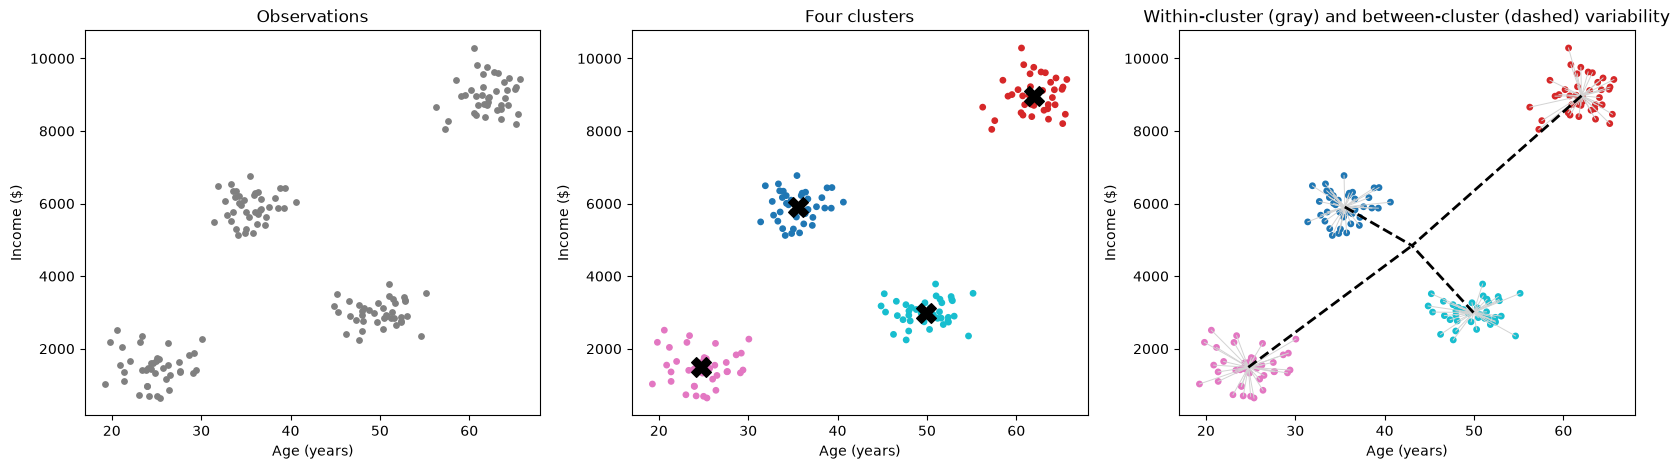

In [2]:
np.random.seed(7)

# Simulating four groups of residents (age, income)
centers = [(25, 1500), (35, 6000), (50, 3000), (62, 9000)]
residents = pd.concat([pd.DataFrame({"age": np.random.normal(cx, 2.5, 40),
                                     "income": np.random.normal(cy, 450, 40)}) for cx, cy in centers],
                      ignore_index=True)

# Standardizing before k-means, since age (years) and income ($) are in different units
kmeans_residents = KMeans(n_clusters=4, n_init=10, random_state=42).fit((residents - residents.mean()) / residents.std())
residents["cluster"] = kmeans_residents.labels_
centroids_residents = residents.groupby("cluster")[["age", "income"]].mean()
overall_mean = residents[["age", "income"]].mean()

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# Figure 9.2: observations
ax[0].scatter(residents["age"], residents["income"], color='gray', s=15)
ax[0].set_title('Observations')

# Figure 9.3: four clusters
ax[1].scatter(residents["age"], residents["income"], c=residents["cluster"], cmap='tab10', s=15)
ax[1].scatter(centroids_residents["age"], centroids_residents["income"], marker='X', s=200, color='black')
ax[1].set_title('Four clusters')

# Figure 9.4: within-cluster and between-cluster variability
for _, row in residents.iterrows():
    c = centroids_residents.loc[row["cluster"]]
    ax[2].plot([row["age"], c["age"]], [row["income"], c["income"]], color='lightgray', linewidth=0.7)
for _, c in centroids_residents.iterrows():
    ax[2].plot([c["age"], overall_mean["age"]], [c["income"], overall_mean["income"]], 'k--', linewidth=2)
ax[2].scatter(residents["age"], residents["income"], c=residents["cluster"], cmap='tab10', s=15)
ax[2].set_title('Within-cluster (gray) and between-cluster (dashed) variability')

for axis in ax:
    axis.set_xlabel('Age (years)')
    axis.set_ylabel('Income ($)')

# Display the chart
plt.show()

The following year, a group of elderly billionaires moves into the city. Rerunning the analysis with four clusters causes the previous groups to disappear (Figure 9.5):

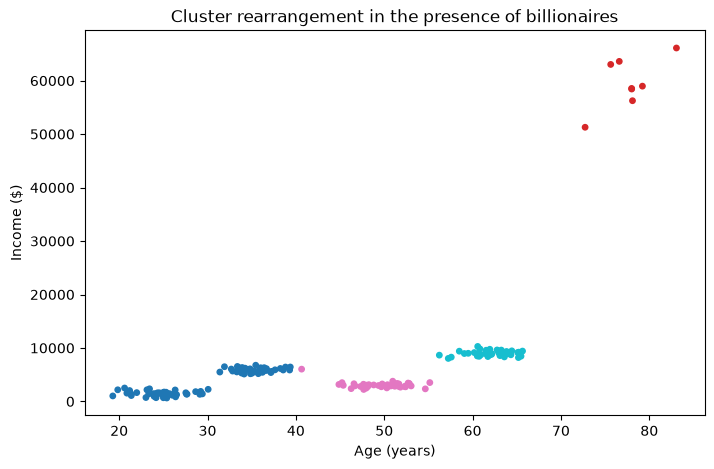

cluster
0    79
1     8
2    41
3    40
dtype: int64


In [3]:
np.random.seed(7)
billionaires = pd.DataFrame({"age": np.random.normal(78, 3, 8), "income": np.random.normal(60000, 6000, 8)})
new_residents = pd.concat([residents[["age", "income"]], billionaires], ignore_index=True)

new_residents["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=42).fit((new_residents - new_residents.mean()) / new_residents.std()).labels_

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(new_residents["age"], new_residents["income"], c=new_residents["cluster"], cmap='tab10', s=15)
ax.set_xlabel('Age (years)')
ax.set_ylabel('Income ($)')
ax.set_title('Cluster rearrangement in the presence of billionaires')

# Display the chart
plt.show()

print(new_residents.groupby("cluster").size())

Notice that the eight billionaires form their own cluster, and to maintain four clusters, two of the original groups merge into one with 79 residents. That is why cluster analysis must be rerun whenever new observations arrive, and outliers should be examined beforehand.

## **Distance and Similarity Measures**

* `Distance (dissimilarity) measures:` used with metric variables. The greater the difference between the values of two observations, the greater the distance and the lower the similarity.
* `Similarity measures:` used with binary variables. The more matching responses (1-1 or 0-0), the greater the similarity.

### **Distance Measures for Metric Variables**

For two observations $p$ and $q$ with $k$ metric variables:

* `Euclidean:` the most widely used, derived from the Pythagorean theorem. $d_{pq} = \sqrt{\sum_{j=1}^{k}(X_{jp} - X_{jq})^2}$
* `Squared Euclidean:` makes distance jumps clearer when values are close. $d_{pq} = \sum_{j=1}^{k}(X_{jp} - X_{jq})^2$
* `Minkowski:` general form, with positive integer $m$. $d_{pq} = \left[\sum_{j=1}^{k}|X_{jp} - X_{jq}|^m\right]^{1/m}$
* `Manhattan (city-block):` the $m = 1$ case. $d_{pq} = \sum_{j=1}^{k}|X_{jp} - X_{jq}|$
* `Chebyshev (maximum):` the $m = \infty$ case, considering only the largest difference. $d_{pq} = \max|X_{jp} - X_{jq}|$
* `Canberra:` for strictly positive variables, ranging from 0 to $k$. $d_{pq} = \sum_{j=1}^{k}\frac{|X_{jp} - X_{jq}|}{X_{jp} + X_{jq}}$

`Pearson correlation` between two rows can also be used, but as a similarity measure (ranging from −1 to 1). It is useful when observations represent time periods and we want to group periods with similar patterns.

$\rho_{pq} = \frac{\sum_{j=1}^{k}(X_{jp} - \overline{X}_p)\cdot(X_{jq} - \overline{X}_q)}{\sqrt{\sum_{j=1}^{k}(X_{jp} - \overline{X}_p)^2}\cdot\sqrt{\sum_{j=1}^{k}(X_{jq} - \overline{X}_q)^2}}$

In [4]:
# Two observations with three metric variables
obs_1 = np.array([3.7, 2.7, 9.1])
obs_2 = np.array([7.8, 8.0, 1.5])

def distance_measures(p, q):

    result = {
        "Euclidean": np.sqrt(np.sum((p - q)**2)),
        "Squared Euclidean": np.sum((p - q)**2),
        "Manhattan": np.sum(np.abs(p - q)),
        "Chebyshev": np.max(np.abs(p - q)),
        "Canberra": np.sum(np.abs(p - q) / (p + q)),
        "Pearson Correlation": np.corrcoef(p, q)[0, 1]
    }

    return pd.Series(result).round(3)

distance_measures(obs_1, obs_2)

Euclidean               10.132
Squared Euclidean      102.660
Manhattan               17.000
Chebyshev                7.600
Canberra                 1.569
Pearson Correlation     -0.993
dtype: float64

Geometrically (Figures 9.6 to 9.8 of the textbook), Euclidean distance comes from applying the Pythagorean theorem twice: first on the projection of the points onto the $X_1 X_2$ plane, $d'_{12} = \sqrt{(X_{11}-X_{12})^2 + (X_{21}-X_{22})^2}$, and then on the triangle formed with the vertical difference, $d_{12} = \sqrt{(d'_{12})^2 + (X_{31}-X_{32})^2}$.

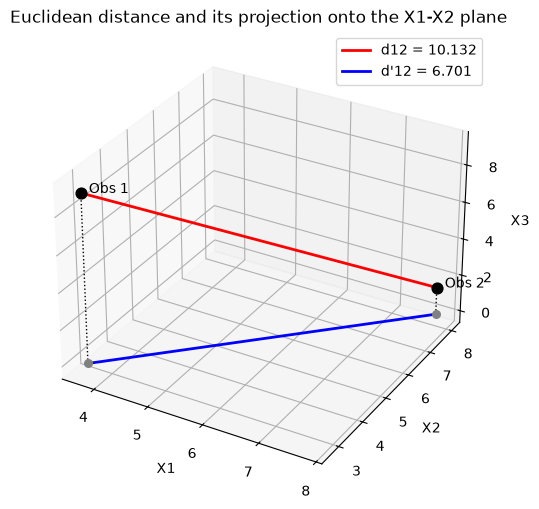

In [5]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

# Points, projections onto the X1-X2 plane, and vertical segments
for point, name in [(obs_1, "Obs 1"), (obs_2, "Obs 2")]:
    ax.scatter(*point, s=60, color='black')
    ax.scatter(point[0], point[1], 0, s=30, color='gray')
    ax.plot([point[0], point[0]], [point[1], point[1]], [0, point[2]], 'k:', linewidth=1)
    ax.text(*point, f'  {name}')

# Euclidean distance d12 and its projection d'12
ax.plot(*zip(obs_1, obs_2), color='red', linewidth=2, label=f'd12 = {np.round(np.sqrt(np.sum((obs_1 - obs_2)**2)), 3)}')
ax.plot([obs_1[0], obs_2[0]], [obs_1[1], obs_2[1]], [0, 0], color='blue', linewidth=2,
        label=f"d'12 = {np.round(np.sqrt(np.sum((obs_1[:2] - obs_2[:2])**2)), 3)}")

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
ax.set_title('Euclidean distance and its projection onto the X1-X2 plane')
ax.legend()

# Display the chart
plt.show()

In [6]:
# Verifying with scipy
for metric in ["euclidean", "sqeuclidean", "cityblock", "chebyshev", "canberra"]:
    print(f"{metric}: {np.round(pdist([obs_1, obs_2], metric=metric)[0], 3)}")

euclidean: 10.132
sqeuclidean: 102.66
cityblock: 17.0
chebyshev: 7.6
canberra: 1.569


Note that different measures produce different results, which can lead to different clusters. See what happens when we add a third observation:

In [7]:
three_obs = pd.DataFrame([[3.7, 2.7, 9.1],
                          [7.8, 8.0, 1.5],
                          [8.9, 1.0, 2.7]],
                         index=["Obs 1", "Obs 2", "Obs 3"], columns=["X1", "X2", "X3"])

pairs = ["1 and 2", "1 and 3", "2 and 3"]
pd.DataFrame({"Euclidean": pdist(three_obs, "euclidean"),
              "Chebyshev": pdist(three_obs, "chebyshev")}, index=pairs).round(3)

,Euclidean,Chebyshev
1 and 2,10.132,7.6
1 and 3,8.420,6.4
2 and 3,7.187,7.0


By Euclidean distance, the most similar observations are 2 and 3 ($d_{23} = 7.187$), whereas by Chebyshev distance they are 1 and 3 ($d_{13} = 6.4$). That is why the choice of distance measure must be justified by the research objectives.

#### **Standardization (Z-scores)**

If variables are measured in different units (income in $, age in years, number of children, etc.), those with larger magnitudes dominate the distance. In this case, we standardize each variable:

$ZX_{ji} = \frac{X_{ji} - \overline{X}_j}{S_j}$

Every standardized variable has a mean of 0 and a standard deviation of 1, without changing the shape of its distribution, contributing equally to the distance.

In [8]:
# Example with variables in different units
customers = pd.DataFrame({
    "Income": [2500, 8000, 4200, 12000, 3100],
    "Age": [23, 45, 31, 52, 28],
    "Children": [0, 2, 1, 3, 0]
})

customers_standardized = (customers - customers.mean()) / customers.std()

print(customers_standardized.agg(["mean", "std"]).round(3))
customers_standardized.round(3)

      Income  Age  Children
mean    -0.0  0.0       0.0
std      1.0  1.0       1.0


,Income,Age,Children
0,-0.866,-1.050,-0.920
1,0.510,0.754,0.614
2,-0.440,-0.394,-0.153
3,1.511,1.328,1.381
4,-0.716,-0.640,-0.920


### **Similarity Measures for Binary Variables**

With binary variables (presence = 1, absence = 0), we count the response pairs for two observations $p$ and $q$:

| $p$ \ $q$ | 1 | 0 |
|---|---|---|
| **1** | a | b |
| **0** | c | d |

* `Simple matching:` the most widely used, giving equal weight to 1-1 and 0-0. $s_{pq} = \frac{a+d}{a+b+c+d}$
* `Jaccard:` ignores 0-0 pairs. $s_{pq} = \frac{a}{a+b+c}$
* `Dice:` doubles the weight of 1-1 pairs. $s_{pq} = \frac{2a}{2a+b+c}$
* `AntiDice:` doubles the weight of mismatches. $s_{pq} = \frac{a}{a+2\cdot(b+c)}$
* `Russell and Rao:` considers only 1-1 pairs in the numerator. $s_{pq} = \frac{a}{a+b+c+d}$
* `Ochiai:` $s_{pq} = \frac{a}{\sqrt{(a+b)\cdot(a+c)}}$
* `Yule:` ranges from −1 to 1. $s_{pq} = \frac{a\cdot d - b\cdot c}{a\cdot d + b\cdot c}$
* `Rogers and Tanimoto:` doubles the weight of mismatched responses. $s_{pq} = \frac{a+d}{a+d+2\cdot(b+c)}$
* `Sneath and Sokal:` doubles the weight of matching responses. $s_{pq} = \frac{2\cdot(a+d)}{2\cdot(a+d)+b+c}$
* `Hamann:` matches minus mismatches, ranging from −1 to 1. $s_{pq} = \frac{(a+d)-(b+c)}{a+b+c+d}$

*Example: when clustering people, the fact that two people eat lobster every day (1-1) is stronger evidence of similarity than both not eating it (0-0). Measures like Jaccard and Dice account for this.*

`NOTE:` *It makes no sense to standardize binary variables.*

In [9]:
# Two observations with seven binary variables
binary_1 = np.array([0, 0, 1, 1, 0, 1, 1])
binary_2 = np.array([0, 1, 1, 1, 1, 0, 1])

def similarity_measures(p, q):

    a = np.sum((p == 1) & (q == 1))
    b = np.sum((p == 1) & (q == 0))
    c = np.sum((p == 0) & (q == 1))
    d = np.sum((p == 0) & (q == 0))

    result = {
        "Simple matching": (a + d) / (a + b + c + d),
        "Jaccard": a / (a + b + c),
        "Dice": 2 * a / (2 * a + b + c),
        "AntiDice": a / (a + 2 * (b + c)),
        "Russell and Rao": a / (a + b + c + d),
        "Ochiai": a / np.sqrt((a + b) * (a + c)),
        "Yule": (a * d - b * c) / (a * d + b * c),
        "Rogers and Tanimoto": (a + d) / (a + d + 2 * (b + c)),
        "Sneath and Sokal": 2 * (a + d) / (2 * (a + d) + b + c),
        "Hamann": ((a + d) - (b + c)) / (a + b + c + d)
    }

    print(f"a = {a} | b = {b} | c = {c} | d = {d}")
    return pd.Series(result).round(3)

similarity_measures(binary_1, binary_2)

a = 3 | b = 1 | c = 2 | d = 1


Simple matching        0.571
Jaccard                0.500
Dice                   0.667
AntiDice               0.333
Russell and Rao        0.429
Ochiai                 0.671
Yule                   0.200
Rogers and Tanimoto    0.400
Sneath and Sokal       0.727
Hamann                 0.143
dtype: float64

## **Clustering Schemes**

Choosing the clustering scheme is just as important as choosing the distance measure.

* `Hierarchical:` build clusters step by step.
    * `Agglomerative:` start with $n$ individual clusters and merge them until a single cluster remains. The most common linkage methods are `single`, `complete`, and `average`.
    * `Divisive:` start with a single cluster and split it until each observation is isolated.
* `Non-hierarchical:` the most popular is `k-means`. The number of clusters is defined beforehand, and observations are assigned based on proximity to cluster centers.

`NOTE:` *When we do not know how many clusters to expect, it is recommended to run a hierarchical scheme first and use the result as input for k-means.*

### **Agglomerative Hierarchical Schemes**

Procedure (Johnson & Wichern, 2007):
1. Start with $n$ individual clusters and the distance matrix $D_0$ between every pair of observations.
2. Merge the two closest observations (smallest distance in $D_0$), leaving $n - 1$ clusters.
3. Recalculate the distances between the new cluster and the others according to the linkage method, and merge the closest pair again.
4. Repeat $n - 1$ times until only one cluster remains.
5. Summarize the process in a tree-shaped chart, the `dendrogram`.

When merging clusters $M$ and $N$, the distance from the new cluster $MN$ to another cluster $W$ depends on the linkage method:

* `Single linkage (nearest neighbor):` uses the minimum distance. Recommended when observations are well separated. $d_{(MN)W} = \min\{d_{MW}; d_{NW}\}$
* `Complete linkage (furthest neighbor):` uses the maximum distance. Recommended when observations are close and we want to identify heterogeneities. $d_{(MN)W} = \max\{d_{MW}; d_{NW}\}$
* `Average linkage (between groups):` uses the mean of all pairwise distances. $d_{(MN)W} = \frac{\sum_{p=1}^{m+n}\sum_{q=1}^{w}d_{pq}}{(m+n)\cdot w}$

#### Example: Entrance Exam Scores

A teacher wants to divide five students into homogeneous groups based on their Math, Physics, and Chemistry entrance exam scores (from 0 to 10). Since all scores are on the same scale, standardization is unnecessary, and we will use Euclidean distance.

In [10]:
exam_scores = pd.DataFrame({
    "math": [3.7, 7.8, 8.9, 7.0, 3.4],
    "physics": [2.7, 8.0, 1.0, 1.0, 2.0],
    "chemistry": [9.1, 1.5, 2.7, 9.0, 5.0]
}, index=["Gabriela", "Luiz Felipe", "Patrícia", "Ovídio", "Leonor"])

exam_scores

,math,physics,chemistry
Gabriela,3.7,2.7,9.1
Luiz Felipe,7.8,8.0,1.5
Patrícia,8.9,1.0,2.7
Ovídio,7.0,1.0,9.0
Leonor,3.4,2.0,5.0


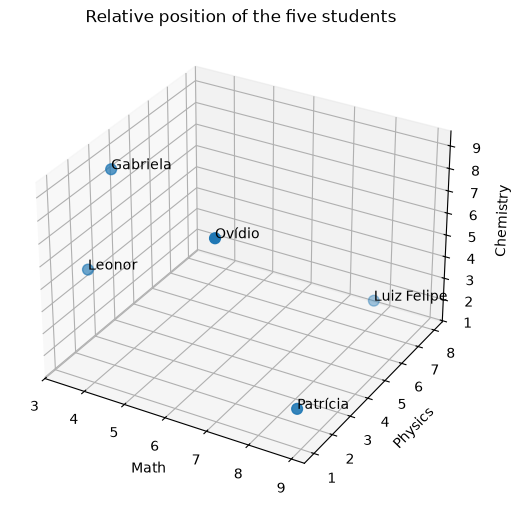

In [11]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

ax.scatter(exam_scores["math"], exam_scores["physics"], exam_scores["chemistry"], s=60)
for name, row in exam_scores.iterrows():
    ax.text(row["math"], row["physics"], row["chemistry"], name)

ax.set_xlabel('Math')
ax.set_ylabel('Physics')
ax.set_zlabel('Chemistry')
ax.set_title('Relative position of the five students')

# Display the chart
plt.show()

In [12]:
# Euclidean distance matrix D0
D0 = pd.DataFrame(squareform(pdist(exam_scores, "euclidean")),
                  index=exam_scores.index, columns=exam_scores.index)
D0.round(3)

,Gabriela,Luiz Felipe,Patrícia,Ovídio,Leonor
Gabriela,0.000,10.132,8.420,3.713,4.170
Luiz Felipe,10.132,0.000,7.187,10.290,8.223
Patrícia,8.420,7.187,0.000,6.580,6.045
Ovídio,3.713,10.290,6.580,0.000,5.474
Leonor,4.170,8.223,6.045,5.474,0.000


To inspect each stage, let's create a function that reproduces the textbook's agglomeration schedule: at each step it calculates the distance between clusters using the chosen method (always from $D_0$) and merges the closest pair.

In [13]:
def agglomeration_schedule(D, method="single"):

    names = list(D.index)
    clusters = [[name] for name in names]
    stages = []

    # Criterion for each linkage method
    criterion = {"single": np.min, "complete": np.max, "average": np.mean}[method]

    while len(clusters) > 1:
        best = None
        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                d = criterion(D.loc[clusters[i], clusters[j]].values)
                if best is None or d < best[0]:
                    best = (d, i, j)

        d, i, j = best
        # Larger group appears as "Cluster" and smaller as "Merged Observation"
        a, b = sorted([clusters[i], clusters[j]], key=len, reverse=True)
        stages.append([" - ".join(a), " - ".join(b), np.round(d, 3)])

        clusters = [g for k, g in enumerate(clusters) if k not in (i, j)] + [a + b]

    result = pd.DataFrame(stages, columns=["Cluster", "Merged Observation", "Distance"])
    result.index = range(1, len(result) + 1)
    result.index.name = "Stage"

    return result

To interpret the dendrograms and visualize the clusters, as in Figures 9.13 to 9.18 of the textbook, let's create two plotting functions: one draws cut lines (I, II, III...) between stages and displays the distance jumps, and the other plots the students in 3D colored by cluster.

In [14]:
def dendrogram_cuts(Z, labels, title):

    heights = Z[:, 2]
    cuts = (heights[:-1] + heights[1:]) / 2  # One line between each pair of stages
    romans = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII"]

    fig, ax = plt.subplots(figsize=(10, 5))
    dendrogram(Z, labels=labels, orientation="right", ax=ax)

    for i, cut in enumerate(cuts):
        ax.axvline(cut, color='red', linestyle='--', linewidth=1)
        ax.text(cut, ax.get_ylim()[1] * 0.97, f' {romans[i]}', ha='left', va='top', color='red')

    ax.set_xlabel('Distance')
    ax.set_title(title)

    # Display the chart
    plt.show()

    # Distance jumps between stages
    jumps = pd.DataFrame({"From": heights[:-1], "To": heights[1:], "Jump": np.diff(heights)},
                         index=[f"Stage {i+1} -> {i+2}" for i in range(len(heights) - 1)])
    return jumps.round(3)


def plot_3d_clusters(data, labels, title, ax=None, centroids=None):

    if ax is None:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(projection='3d')

    ax.scatter(data.iloc[:, 0], data.iloc[:, 1], data.iloc[:, 2], c=labels, cmap='tab10', s=80, vmin=0, vmax=9)
    for name, row in data.iterrows():
        ax.text(row.iloc[0], row.iloc[1], row.iloc[2], f'  {name}', fontsize=9)

    if centroids is not None:
        ax.scatter(centroids.iloc[:, 0], centroids.iloc[:, 1], centroids.iloc[:, 2],
                   marker='X', s=200, color='black', label='Centroids')
        ax.legend()

    ax.set_xlabel('Math')
    ax.set_ylabel('Physics')
    ax.set_zlabel('Chemistry')
    ax.set_title(title)
    return ax

##### *Single Linkage*

In [15]:
agglomeration_schedule(D0, method="single")

,Cluster,Merged Observation,Distance
Stage,,,
1,Gabriela,Ovídio,3.713
2,Gabriela - Ovídio,Leonor,4.170
3,Gabriela - Ovídio - Leonor,Patrícia,6.045
4,Gabriela - Ovídio - Leonor - Patrícia,Luiz Felipe,7.187


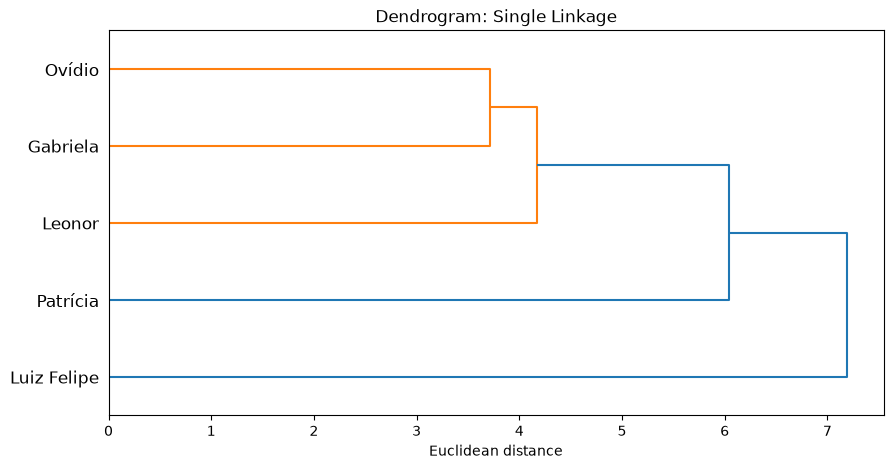

In [16]:
# Dendrogram (scipy uses the same logic)
single_linkage = linkage(pdist(exam_scores, "euclidean"), method="single")

fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(single_linkage, labels=exam_scores.index.tolist(), orientation="right", ax=ax)
ax.set_xlabel('Euclidean distance')
ax.set_title('Dendrogram: Single Linkage')

# Display the chart
plt.show()

Notice that Gabriela and Ovídio merge first (3.713), then Leonor joins (4.170), followed by Patrícia (6.045), and finally Luiz Felipe (7.187).

To read the dendrogram, we look at the `distance jumps` from one stage to the next. The largest jump (from 4.170 to 6.045) happens when Patrícia enters the group, signaling that she is not very similar to the others. A useful criterion is to choose the number of clusters from the stage immediately preceding the large jump: here, `three clusters`—Gabriela-Ovídio-Leonor, Patrícia, and Luiz Felipe.

`NOTE:` *If the jumps are very small, squared Euclidean distance helps make them clearer.*

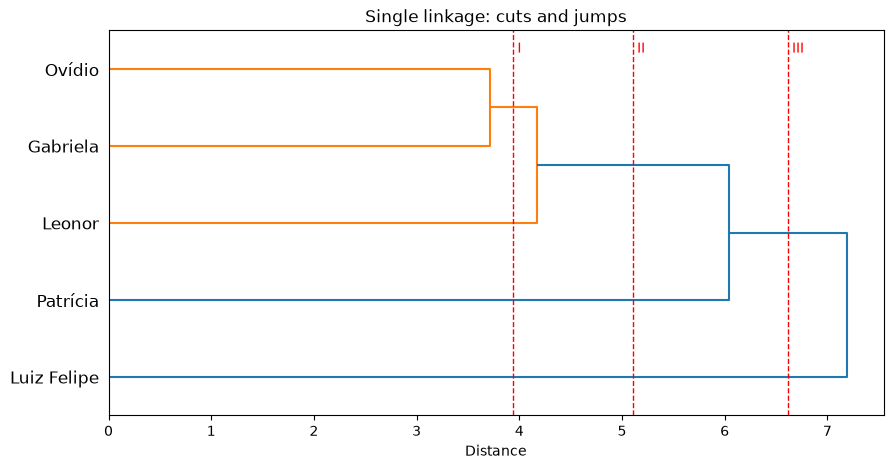

,From,To,Jump
Stage 1 -> 2,3.713,4.170,0.457
Stage 2 -> 3,4.170,6.045,1.875
Stage 3 -> 4,6.045,7.187,1.142


In [17]:
# Figures 9.13 and 9.14: cut lines and distance jumps
dendrogram_cuts(single_linkage, exam_scores.index.tolist(), 'Single linkage: cuts and jumps')

Notice that line I cuts the dendrogram into four clusters, line II into three, and line III into two. The largest jump (1.875) occurs when Patrícia merges, so we keep the solution from line II.

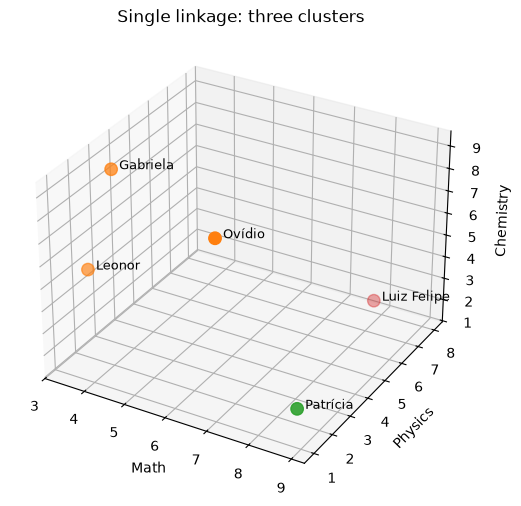

In [18]:
# Figure 9.15: clusters suggested by single linkage (3 clusters)
plot_3d_clusters(exam_scores[["math", "physics", "chemistry"]],
                 fcluster(single_linkage, t=3, criterion="maxclust"),
                 'Single linkage: three clusters')

# Display the chart
plt.show()

##### *Complete Linkage*

In [19]:
agglomeration_schedule(D0, method="complete")

,Cluster,Merged Observation,Distance
Stage,,,
1,Gabriela,Ovídio,3.713
2,Gabriela - Ovídio,Leonor,5.474
3,Luiz Felipe,Patrícia,7.187
4,Gabriela - Ovídio - Leonor,Luiz Felipe - Patrícia,10.290


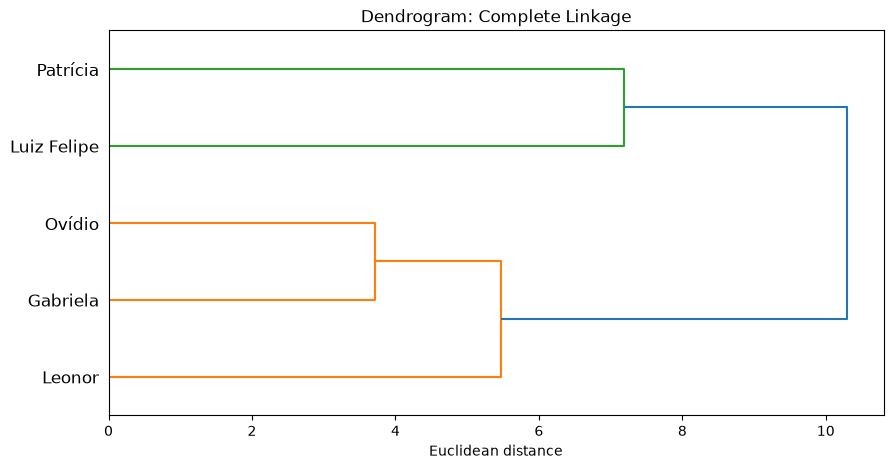

In [20]:
complete_linkage = linkage(pdist(exam_scores, "euclidean"), method="complete")

fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(complete_linkage, labels=exam_scores.index.tolist(), orientation="right", ax=ax)
ax.set_xlabel('Euclidean distance')
ax.set_title('Dendrogram: Complete Linkage')

# Display the chart
plt.show()

Notice that in the third stage the order changes: instead of Patrícia joining the first group, she merges with Luiz Felipe (7.187). With three clusters, the solution is the same as single linkage, but with two clusters it changes: Gabriela-Ovídio-Leonor on one side and Luiz Felipe-Patrícia on the other.

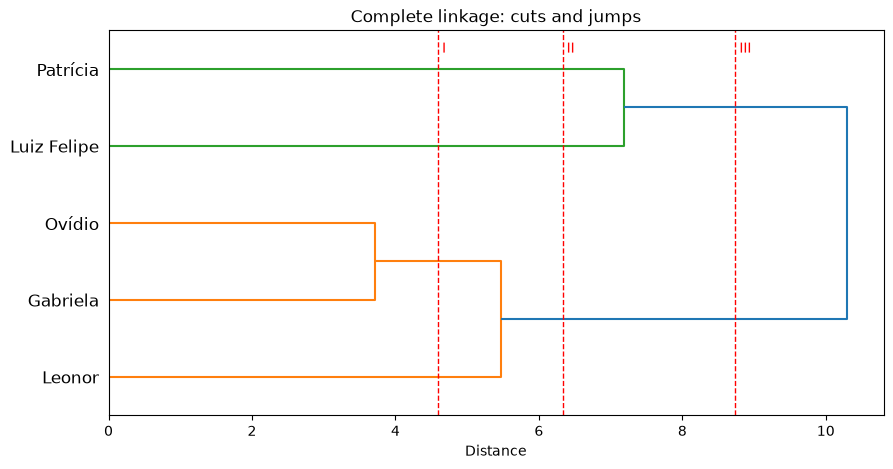

,From,To,Jump
Stage 1 -> 2,3.713,5.474,1.760
Stage 2 -> 3,5.474,7.187,1.713
Stage 3 -> 4,7.187,10.290,3.103


In [21]:
# Figure 9.17: cut lines and distance jumps
dendrogram_cuts(complete_linkage, exam_scores.index.tolist(), 'Complete linkage: cuts and jumps')

Notice that in complete linkage, the largest jump (3.103) is the final merge of the two groups, so the two-cluster solution (line III) is also reasonable here.

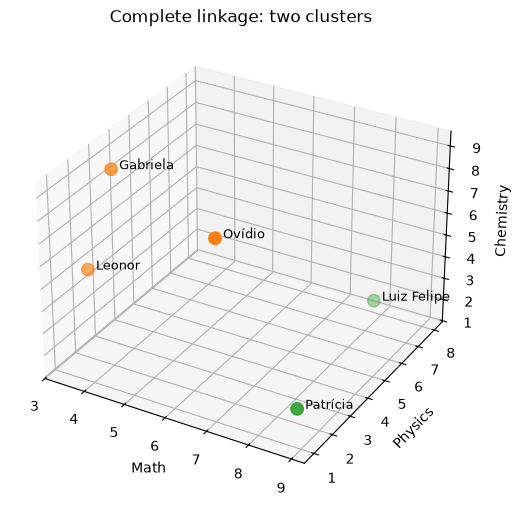

In [22]:
# Figure 9.18: clusters suggested by complete linkage (2 clusters)
plot_3d_clusters(exam_scores[["math", "physics", "chemistry"]],
                 fcluster(complete_linkage, t=2, criterion="maxclust"),
                 'Complete linkage: two clusters')

# Display the chart
plt.show()

##### *Average Linkage*

In [23]:
agglomeration_schedule(D0, method="average")

,Cluster,Merged Observation,Distance
Stage,,,
1,Gabriela,Ovídio,3.713
2,Gabriela - Ovídio,Leonor,4.822
3,Gabriela - Ovídio - Leonor,Patrícia,7.015
4,Gabriela - Ovídio - Leonor - Patrícia,Luiz Felipe,8.958


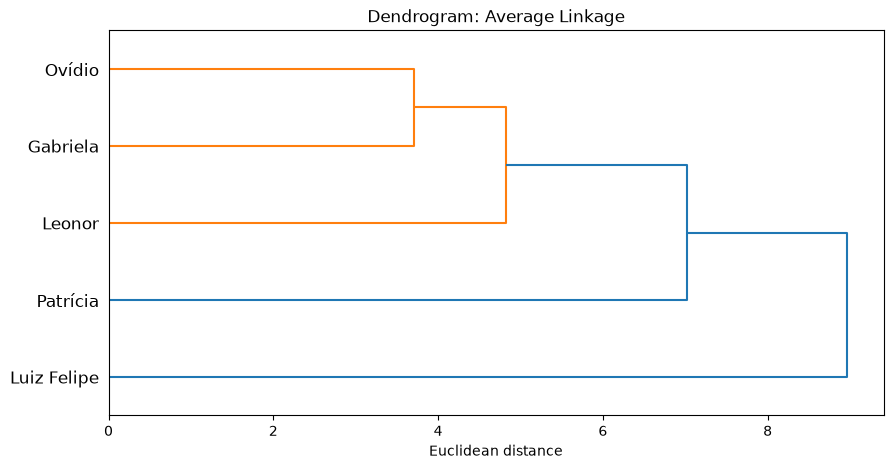

In [24]:
average_linkage = linkage(pdist(exam_scores, "euclidean"), method="average")

fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(average_linkage, labels=exam_scores.index.tolist(), orientation="right", ax=ax)
ax.set_xlabel('Euclidean distance')
ax.set_title('Dendrogram: Average Linkage')

# Display the chart
plt.show()

Notice that average linkage preserves the same order and cluster assignment as single linkage, only with different distances. This indicates that the observations are well separated from each other. If they were closer, average linkage would agree with complete linkage.

`NOTE:` *That is why the textbook recommends applying all three methods and comparing their dendrograms before deciding on the number of clusters.*

In [25]:
# Assigning observations to 3 clusters (cutting the single-linkage dendrogram)
exam_scores["hierarchical_cluster"] = fcluster(single_linkage, t=3, criterion="maxclust")
exam_scores

,math,physics,chemistry,hierarchical_cluster
Gabriela,3.7,2.7,9.1,1
Luiz Felipe,7.8,8.0,1.5,3
Patrícia,8.9,1.0,2.7,2
Ovídio,7.0,1.0,9.0,1
Leonor,3.4,2.0,5.0,1


### **Multidimensional Scaling (MDS)**

From the distance matrix, `multidimensional scaling` (MDS) generates a two-dimensional chart showing the relative positions of observations, regardless of the number of variables.

/home/weder/Documentos/Projects/Unievangelica/ArtficialInteligence/00_Class/practical_statistics_for_data_scientists_2026/.venv/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/home/weder/Documentos/Projects/Unievangelica/ArtficialInteligence/00_Class/practical_statistics_for_data_scientists_2026/.venv/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


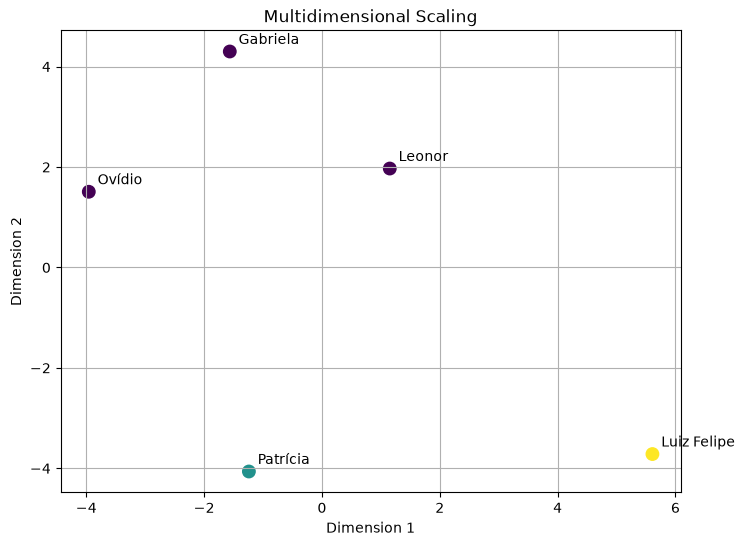

In [26]:
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42, n_init=4)
coordinates = mds.fit_transform(D0.values)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(coordinates[:, 0], coordinates[:, 1], s=80, c=exam_scores["hierarchical_cluster"], cmap="viridis")
for name, (x, y) in zip(exam_scores.index, coordinates):
    ax.text(x + 0.15, y + 0.15, name)

ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('Multidimensional Scaling')
plt.grid(True)

# Display the chart
plt.show()

### **Non-Hierarchical K-Means Scheme**

The number of clusters $K$ is defined beforehand, either by the researcher's criteria or based on the result of a hierarchical scheme.

Procedure (Johnson & Wichern, 2007):
1. Arbitrarily assign observations to the $K$ clusters and compute their centroids.
2. Pick an observation and reassign it to the cluster with the nearest centroid. The centroids of both the gaining and losing clusters are recalculated.
3. Repeat until no observation can be reassigned.

When observation $p$ enters or leaves a cluster with $N$ observations and centroid $\overline{x}$:

$\overline{x}_{new} = \frac{N\cdot\overline{x} + x_p}{N + 1}$ (inclusion) and $\overline{x}_{new} = \frac{N\cdot\overline{x} - x_p}{N - 1}$ (exclusion)

`NOTE:` *Because it does not need to recalculate the distance matrix at every step, k-means scales to much larger datasets than hierarchical methods. Variables must also be standardized if they are measured in different units.*

In [27]:
def kmeans_reallocation(data, initial_assignment, history=None):

    X = data.values
    names = list(data.index)
    labels = np.array(initial_assignment)
    changed = True

    if history is not None:
        history.append(labels.copy())

    while changed:
        changed = False
        for p in range(len(X)):
            current = labels[p]
            if np.sum(labels == current) == 1:
                continue  # Do not empty a cluster

            # Distance from p to each cluster centroid, assuming p is included in it
            distances = {}
            for c in np.unique(labels):
                members = (labels == c)
                members[p] = True
                centroid = X[members].mean(axis=0)
                distances[c] = np.sqrt(np.sum((X[p] - centroid)**2))

            best = min(distances, key=distances.get)
            if best != current:
                print(f"{names[p]} moves from cluster {current} to cluster {best} (distance {np.round(distances[best], 3)})")
                labels[p] = best
                changed = True
                if history is not None:
                    history.append(labels.copy())

    return labels

#### Example: K-Means with K = 3

We start from the textbook's arbitrary initial assignment: Gabriela and Luiz Felipe in cluster 1, Patrícia and Ovídio in cluster 2, and Leonor in cluster 3.

In [28]:
scores = exam_scores[["math", "physics", "chemistry"]]

# Gabriela, Luiz Felipe, Patrícia, Ovídio, Leonor
initial_assignment = [1, 1, 2, 2, 3]

kmeans_steps = []
exam_scores["kmeans_cluster"] = kmeans_reallocation(scores, initial_assignment, history=kmeans_steps)
exam_scores

Gabriela moves from cluster 1 to cluster 3 (distance 2.085)
Ovídio moves from cluster 2 to cluster 3 (distance 2.791)


,math,physics,chemistry,hierarchical_cluster,kmeans_cluster
Gabriela,3.7,2.7,9.1,1,3
Luiz Felipe,7.8,8.0,1.5,3,1
Patrícia,8.9,1.0,2.7,2,2
Ovídio,7.0,1.0,9.0,1,3
Leonor,3.4,2.0,5.0,1,3


In [29]:
# Final centroids
centroids = scores.groupby(exam_scores["kmeans_cluster"]).mean()
centroids.round(2)

,math,physics,chemistry
kmeans_cluster,,,
1,7.8,8.0,1.5
2,8.9,1.0,2.7
3,4.7,1.9,7.7


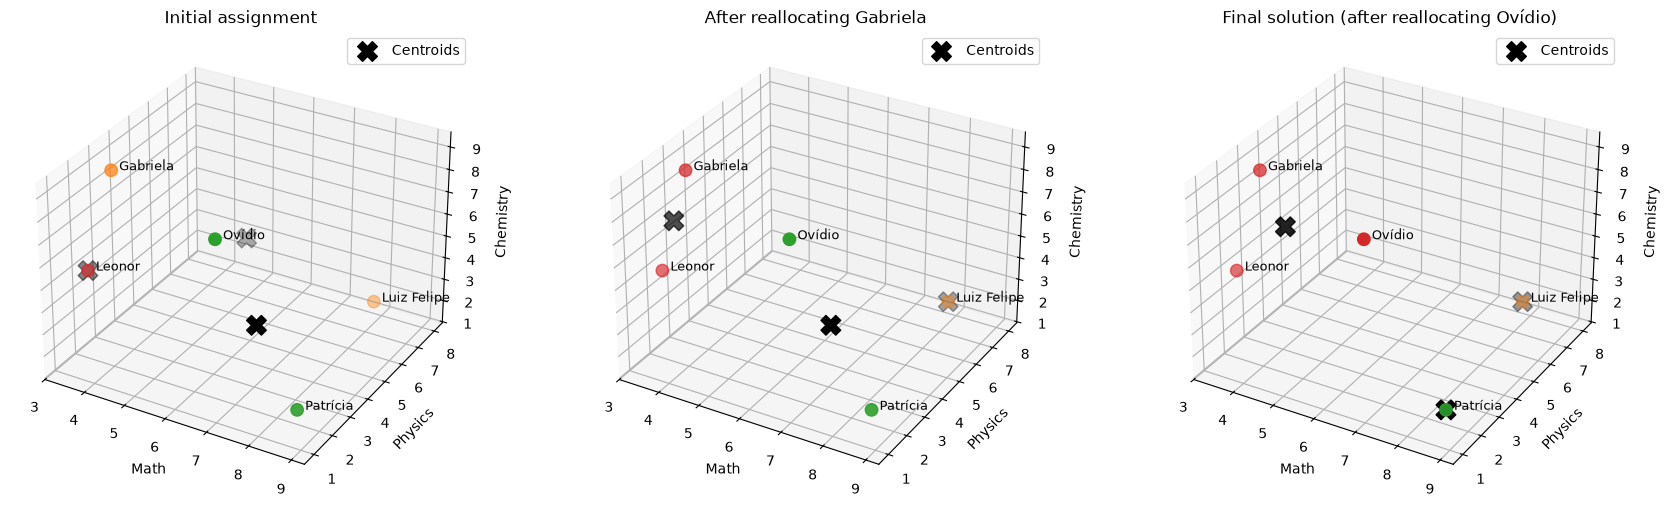

In [30]:
# Figures 9.21 to 9.23: initial assignment, after moving Gabriela, and final solution
fig = plt.figure(figsize=(21, 6))
titles = ['Initial assignment', 'After reallocating Gabriela', 'Final solution (after reallocating Ovídio)']

for i, (labels, title) in enumerate(zip(kmeans_steps, titles)):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    step_centroids = scores.groupby(labels).mean()
    plot_3d_clusters(scores, labels, title, ax=ax, centroids=step_centroids)

# Display the chart
plt.show()

In [31]:
# Euclidean distances between each observation and each centroid
pd.DataFrame(cdist(scores, centroids), index=scores.index,
             columns=[f"Cluster {c}" for c in centroids.index]).round(3)

,Cluster 1,Cluster 2,Cluster 3
Gabriela,10.132,8.420,1.897
Luiz Felipe,0.000,7.187,9.234
Patrícia,7.187,0.000,6.592
Ovídio,10.290,6.580,2.791
Leonor,8.223,6.045,2.998


Notice that Gabriela and Ovídio were reallocated to Leonor's group, and the final solution has the same three clusters as single and average linkage: Gabriela-Ovídio-Leonor, Luiz Felipe, and Patrícia.

In [32]:
# Verifying with sklearn's KMeans (multiple random initializations)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(scores)
pd.crosstab(exam_scores["kmeans_cluster"], kmeans.labels_, rownames=["Reallocation"], colnames=["sklearn"])

sklearn,0,1,2
Reallocation,,,
1,0,0,1
2,0,1,0
3,3,0,0


`NOTE:` *scikit-learn numbers the clusters differently, but the crosstab shows that the partition is identical. Rerunning k-means with multiple initial assignments (the `n_init` parameter) helps evaluate the stability of the solution.*

#### **ANOVA for Each Variable**

After clustering, we check with one-way ANOVA (Module 07) whether each variable has different means across clusters:

$H_0:$ the variable has the same mean across all clusters

$H_1:$ the variable has a different mean in at least one cluster

$F = \frac{\sum_{k=1}^{K}N_k\cdot(\overline{X}_k - \overline{X})^2/(K-1)}{\sum_{k=1}^{K}\sum_{i}(X_{ki} - \overline{X}_k)^2/(n-K)}$

Variables with higher $F$ values contribute the most to cluster formation.

In [33]:
anova_clusters = []
for variable in scores.columns:
    groups = [scores.loc[exam_scores["kmeans_cluster"] == c, variable] for c in sorted(exam_scores["kmeans_cluster"].unique())]
    f_cal, p_value = stats.f_oneway(*groups)
    anova_clusters.append([variable, f_cal, p_value])

anova_clusters = pd.DataFrame(anova_clusters, columns=["Variable", "F", "Sig. F"]).set_index("Variable")
print(f"Critical F (5%; 2 and 2 df): {np.round(stats.f.ppf(0.95, 2, 2), 2)}")
anova_clusters.round(3)

Critical F (5%; 2 and 2 df): 19.0


,F,Sig. F
Variable,,
math,2.079,0.325
physics,22.337,0.043
chemistry,3.506,0.222


Notice that only the physics score has a significantly different mean across clusters (F = 22.337 > 19.00, Sig. F = 0.043). Math (Sig. F = 0.325) and chemistry (Sig. F = 0.222) do not differ significantly, largely due to the small sample size (only five students).

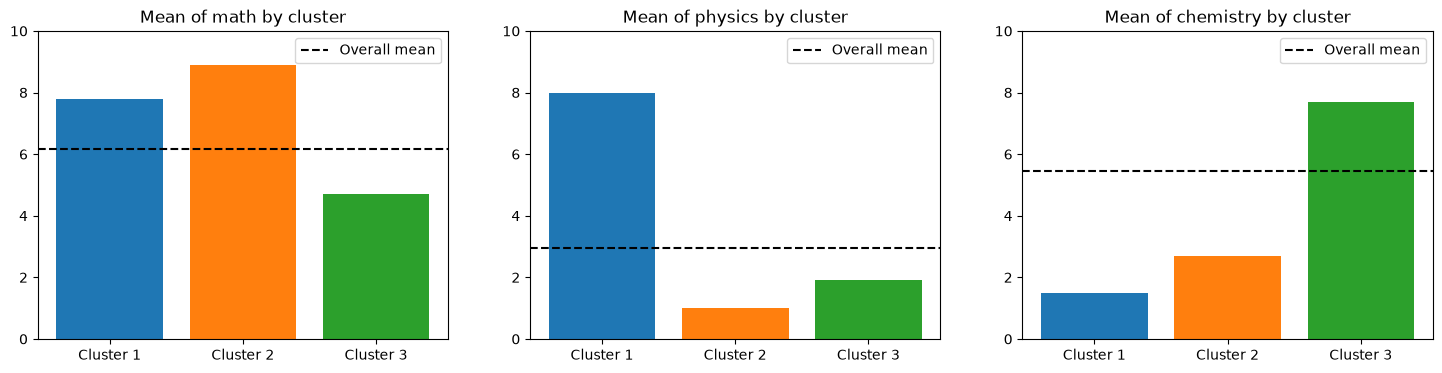

In [34]:
# Figures 9.43 to 9.45: means of each variable across the three clusters
cluster_means = scores.groupby(exam_scores["kmeans_cluster"]).mean()

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for axis, variable in zip(ax, scores.columns):
    axis.bar([f"Cluster {c}" for c in cluster_means.index], cluster_means[variable], color=['C0', 'C1', 'C2'])
    axis.axhline(scores[variable].mean(), color='black', linestyle='--', label='Overall mean')
    axis.set_title(f'Mean of {variable} by cluster')
    axis.set_ylim(0, 10)
    axis.legend()

# Display the chart
plt.show()

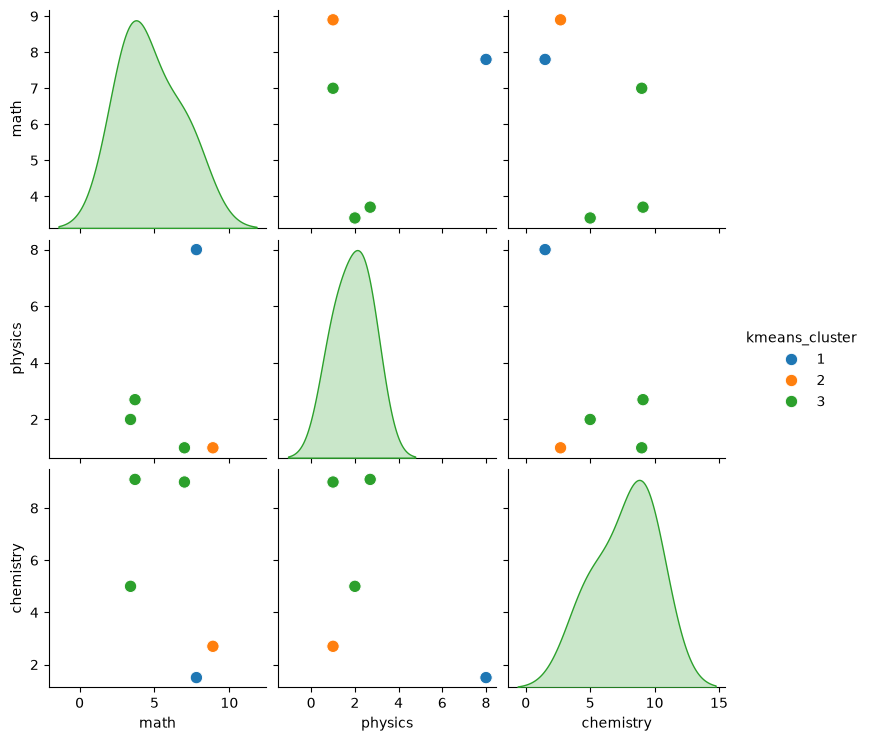

In [35]:
# Figure 9.75: interrelationship of variables and position of observations in each cluster
sns.pairplot(exam_scores[["math", "physics", "chemistry", "kmeans_cluster"]],
             hue="kmeans_cluster", palette="tab10", plot_kws={"s": 80});

`NOTE:` *If a variable does not contribute to cluster formation, the textbook recommends rerunning the analysis without it. The resulting cluster variable can also be used later in other techniques, such as correspondence analysis or multinomial logistic regression.*

## **Appendix: Multivariate Outlier Detection**

Because clusters are sensitive to outliers, it is worth identifying them beforehand. The textbook presents the `BACON` algorithm (*Blocked Adaptive Computationally Efficient Outlier Nominators*) by Billor, Hadi, and Velleman (2000), based on `Mahalanobis distance`, which is invariant to variable units:

$d_i = \sqrt{(x_i - \overline{x})^T\cdot S^{-1}\cdot(x_i - \overline{x})}$

where $S$ is the covariance matrix.

Procedure:
1. Select the $m$ observations ($m = 4\cdot k$, or slightly more if there are repeated values) with the smallest Mahalanobis distance relative to the entire sample. They form the basic subset $M$.
2. Compute the distance of every observation to the mean of $M$, using the covariance matrix of $M$.
3. Include in $M$ all observations with a distance below a threshold based on the $\chi^2$ distribution (with $\alpha = 0.15$, Stata's default), corrected for sample size.
4. Repeat steps 2 and 3 until $M$ stops changing. Any observation left outside is flagged as an outlier.

In [36]:
def bacon(data, alpha=0.15):

    X = np.asarray(data, dtype=float)
    n, k = X.shape

    def mahalanobis(X, mean, cov):
        diff = X - mean
        return np.sqrt(np.einsum('ij,jk,ik->i', diff, np.linalg.pinv(cov), diff))

    # Step 1: initial basic subset with the m smallest distances
    d = mahalanobis(X, X.mean(axis=0), np.cov(X, rowvar=False))
    order = np.argsort(d)
    m = 4 * k
    # If there are repeated values, increase m until the covariance matrix is invertible
    while np.linalg.matrix_rank(np.cov(X[order[:m]], rowvar=False)) < k:
        m += k
    basic = order[:m]

    while True:
        # Step 2: distances relative to the basic subset
        subsample = X[basic]
        r = len(basic)
        d = mahalanobis(X, subsample.mean(axis=0), np.cov(subsample, rowvar=False))

        # Step 3: chi-square threshold with correction factor
        h = (n + k + 1) // 2
        c_np = 1 + (k + 1) / (n - k) + 2 / (n - 1 - 3 * k)
        c_hr = max(0, (h - r) / (h + r))
        threshold = (c_np + c_hr) * np.sqrt(chi2.ppf(1 - alpha / n, k))
        new_basic = np.where(d < threshold)[0]

        # Step 4: stop when the basic subset stops changing
        if set(new_basic) == set(basic):
            break
        basic = new_basic

    outlier = np.ones(n, dtype=int)
    outlier[basic] = 0

    return outlier

#### Example with Simulated Data

The textbook uses the `Bacon.dta` dataset, containing income, age, and years since graduation for 20,000 engineers, which is not included in this repository. To demonstrate the algorithm, let's simulate a similar dataset and insert the four outliers found in the textbook.

In [37]:
np.random.seed(42)
n = 20000

# Simulating engineers: income grows with years since graduation
age = np.random.randint(23, 61, n)
years_grad = np.clip(age - np.random.randint(21, 31, n), 0, None)  # Graduated between ages 21 and 30
income = np.clip(4000 + 280 * years_grad + np.random.normal(0, 1200, n), 1000, None)

engineers = pd.DataFrame({"income": income.round(2), "age": age, "years_grad": years_grad})

# Inserting the four outliers from the textbook
textbook_outliers = pd.DataFrame({"income": [30869.93, 34773.54, 41191.15, 32924.19],
                                  "age": [30, 42, 50, 31],
                                  "years_grad": [15, 17, 21, 16]})
engineers = pd.concat([engineers, textbook_outliers], ignore_index=True)

engineers.describe().round(2)

,income,age,years_grad
count,20004.00,20004.00,20004.00
mean,8533.81,41.46,16.15
std,3309.56,10.89,10.89
min,1000.00,23.00,0.00
25%,5868.05,32.00,7.00
50%,8477.47,41.00,16.00
75%,11139.71,51.00,25.00
max,41191.15,60.00,39.00


In [38]:
engineers["outbacon"] = bacon(engineers[["income", "age", "years_grad"]])

print(f"Total observations: {len(engineers)}")
print(f"BACON outliers: {engineers['outbacon'].sum()}")
engineers[engineers["outbacon"] == 1]

Total observations: 20004
BACON outliers: 4


,income,age,years_grad,outbacon
20000,30869.93,30,15,1
20001,34773.54,42,17,1
20002,41191.15,50,21,1
20003,32924.19,31,16,1


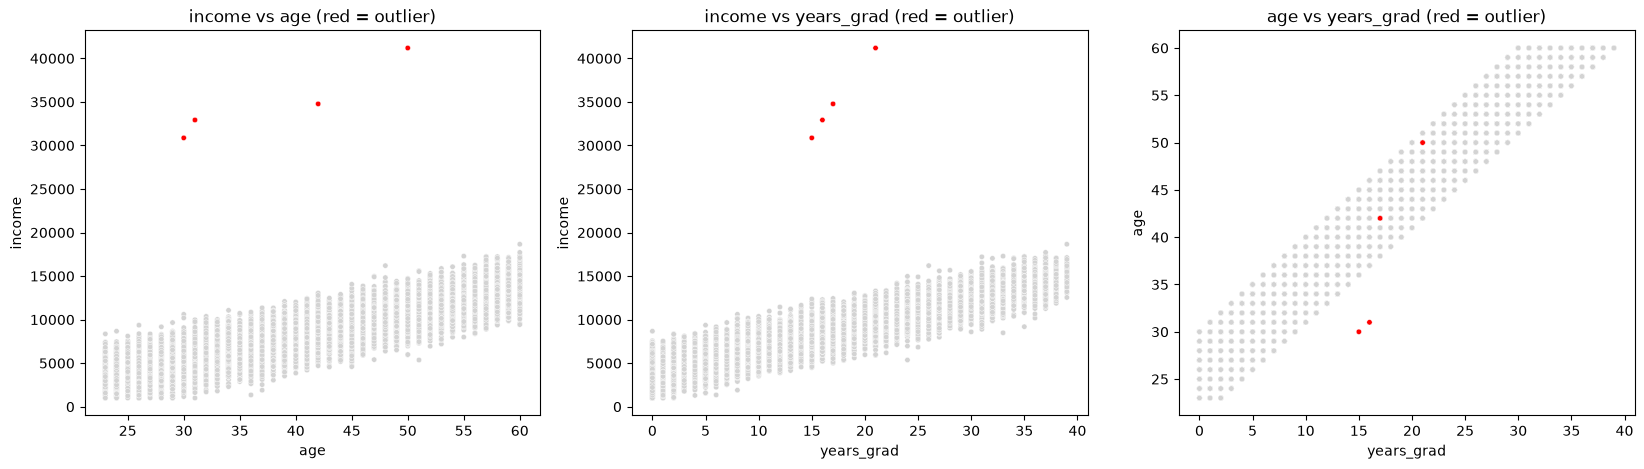

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

variable_pairs = [("age", "income"), ("years_grad", "income"), ("years_grad", "age")]
for axis, (x, y) in zip(ax, variable_pairs):
    sns.scatterplot(data=engineers, x=x, y=y, hue="outbacon", palette={0: "lightgray", 1: "red"},
                    s=15, ax=axis, legend=False)
    axis.set_title(f'{y} vs {x} (red = outlier)')

# Display the chart
plt.show()

Notice that among the 20,004 observations, BACON identified exactly the four inserted engineers—the same ones found by Stata's `bacon` command in the textbook. Their income is far above what is expected for their age and years since graduation, which is clearly visible in the income scatter plots.

`NOTE:` *What to do with outliers is the researcher's decision: they can be excluded from the analysis, but understanding why they are discrepant can also lead to valuable insights.*

## **Cluster Analysis Exercises**

The Chapter 9 exercises in the textbook use datasets that accompany the book and are not included in this repository:

1. `Bolsa de Estudo.dta`: cluster 100 students by age and income (complete linkage, squared Euclidean distance, with Z-score standardization) and investigate outliers.
2. `Regional Varejista.dta`: cluster 18 stores by service, assortment, and organization (single linkage, k-means, ANOVA, and multidimensional scaling).
3. `Pesquisa Binária.dta`: cluster 35 companies based on 50 binary responses (average linkage and simple matching).
4. `Hortifrúti.dta`: cluster 16 weeks of banana, orange, and apple sales using Pearson correlation between rows.

`NOTE:` *To solve them, place the datasets in the `data/` folder and apply the same functions from this notebook (`agglomeration_schedule`, `linkage`, `KMeans`, `MDS`, and `bacon`).*